In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import xarray as xr

from fast_o3_iv import utils, metrics
import fast_o3_iv.bias_correction as bc
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig


In [3]:
# load observation osdma8
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))


In [7]:
# load modeled monthly mda8o3
config_hist = DatasetConfig(
            source_id = 'CESM2',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )

hist_anm = utils.load_or_aggregate_results(
    "inference",
    config_hist,
     "GPR-local",
)

No existing dataset found. Creating it now.
Found 13 parquet files
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/historical/LE2-1001.001/setC/GPR-local/NCAR.CESM2.historical.LE2-1001.001.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/historical/LE2-1021.002/setC/GPR-local/NCAR.CESM2.historical.LE2-1021.002.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/historical/LE2-1041.003/setC/GPR-local/NCAR.CESM2.historical.LE2-1041.003.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/historical/LE2-1061.004/setC/GPR-local/NCAR.CESM2.historical.LE2-1061.004.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/historical/LE2-1081.005/setC/GPR-local/NCAR.CESM2.historical

In [8]:
config_ssp245 = DatasetConfig(
            source_id = 'CESM2',
            cmip_experiment_id = 'ssp245',
            variable_setname = 'setC',
            year_range = range(2015,2055)
        )
ssp245_anm = utils.load_or_aggregate_results(
    "inference",
    config_ssp245,
     "GPR-local",
)

No existing dataset found. Creating it now.
Found 16 parquet files
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/ssp245/001/setC/GPR-local/NCAR.CESM2.ssp245.001.setC.2015-2054.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/ssp245/002/setC/GPR-local/NCAR.CESM2.ssp245.002.setC.2015-2054.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/ssp245/003/setC/GPR-local/NCAR.CESM2.ssp245.003.setC.2015-2054.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/ssp245/004/setC/GPR-local/NCAR.CESM2.ssp245.004.setC.2015-2054.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2/ssp245/005/setC/GPR-local/NCAR.CESM2.ssp245.005.setC.2015-2054.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/

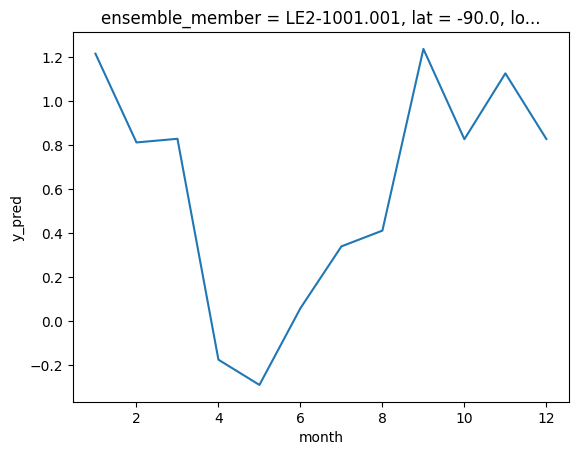

In [9]:
# check that seasonal cycle is removed from original anomalies
hist_anm['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [11]:
# add climatology (only required if target == mda8o3_anm (setC))

train_config_hist = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )
train_config_ssp245 = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )

hist = utils.add_mda8o3_climatology(hist_anm, train_config_hist) 
ssp245 = utils.add_mda8o3_climatology(ssp245_anm, train_config_ssp245) 

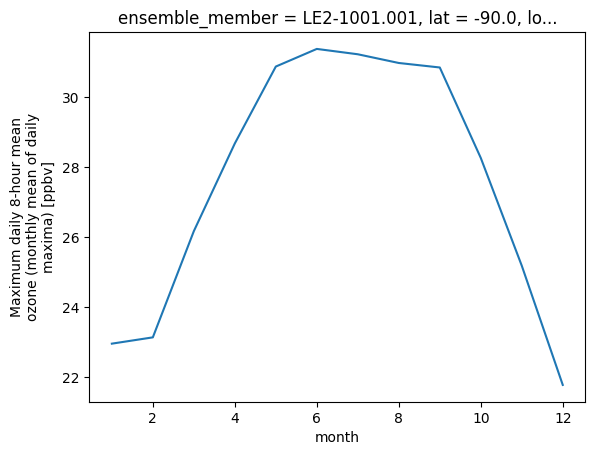

In [12]:
# check that seasonal cycle is fixed
hist['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [13]:
#convert monthly mda8o3 to osdma8 
hist_osdma8 = metrics.calc_osdma8(hist)
ssp245_osdma8 = metrics.calc_osdma8(ssp245)

In [15]:
# calculate scaling factor based on historical mod vs obs osdma8
scaling_factor, obs_base, mod_base = bc.get_bc_scaling_factor(hist_osdma8, ramp_osdma8)

In [16]:
# apply bias correction
hist_osdma8_bc = bc.bias_correct(hist_osdma8, scaling_factor)
ssp245_osdma8_bc = bc.bias_correct(ssp245_osdma8, scaling_factor)

In [17]:
hist_osdma8_bc

<xarray.Dataset> Size: 461MB
Dimensions:          (time: 40, ensemble_member: 13, lat: 192, lon: 288)
Coordinates:
  * time             (time) datetime64[us] 320B 1975-01-01 ... 2014-01-01
  * ensemble_member  (ensemble_member) object 104B 'LE2-1001.001' ... 'LE2-12...
  * lat              (lat) float64 2kB -90.0 -89.06 -88.12 ... 88.12 89.06 90.0
  * lon              (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 356.2 357.5 358.8
Data variables:
    y_pred           (time, lat, lon, ensemble_member) float64 230MB 30.04 .....
    y_pred_bc        (time, lat, lon, ensemble_member) float64 230MB nan ... nan
    scaling_factor   (lat, lon) float64 442kB nan nan nan nan ... nan nan nan
Attributes:
    units:         ppbv
    mixing_ratio:  
    long_name:     Ozone season daily 8-hour mean ozone (OSDMA8)
    cell_methods:  time: mean
    note:          Calculated after shifting data to local standard time (no ...

In [19]:
# save to netcdf
file_path = bc.return_osdma8_bc_path("inference", config_hist, "GPR-local")
hist_osdma8_bc.to_netcdf(file_path)

file_path = bc.return_osdma8_bc_path("inference", config_ssp245, "GPR-local")
ssp245_osdma8_bc.to_netcdf(file_path)